# PC-RGNN: honest PCL graph-processing demonstration

This notebook verifies eight real PCL test-corpus files pinned by SHA-256. It distinguishes raw source files, derived normalized/subsampled views, and synthetic midpoint-completion points. The filename-to-class mapping is manual, and the corpus does not support a trustworthy class-balanced holdout, so this notebook intentionally reports no classification accuracy.

## Reproducibility and evaluation boundary

- Raw source: `data/pc_rgnn/*.pcd`, eight files, one `source_id` per file.
- Derived data: normalized and fixed-size views; these retain the source identifier.
- Synthetic data: midpoint interpolation used only to demonstrate graph completion.
- Evaluation: source-aware audit only. Augmented copies are never treated as independent scans.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'data' / 'pc_rgnn').exists():
    ROOT = ROOT.parent
MANIFEST_PATH = ROOT / 'data' / 'pc_rgnn' / 'provenance.json'
manifest = json.loads(MANIFEST_PATH.read_text())
DATA_DIR = ROOT / 'data' / 'pc_rgnn'
print('project root:', ROOT)
print('pinned revision:', manifest['pinned_revision'])

project root: /home/aliaqil/Desktop/projects/pcrgnn
pinned revision: 66e1d0ea8cc3fa54820eb38e18ad0adac6345b94


In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def read_ascii_pcd(path):
    header = []
    with path.open('rb') as handle:
        for raw_line in handle:
            line = raw_line.decode('ascii').strip()
            header.append(line)
            if line.upper().startswith('DATA'):
                break
    fields = next(line.split()[1:] for line in header if line.upper().startswith('FIELDS'))
    data_line = next(line for line in header if line.upper().startswith('DATA'))
    if data_line.lower() != 'data ascii':
        raise ValueError(f'{path.name}: expected DATA ascii')
    values = np.loadtxt(path, skiprows=len(header), ndmin=2)
    xyz = values[:, [fields.index(axis) for axis in ('x', 'y', 'z')]].astype(np.float32)
    if not np.isfinite(xyz).all():
        raise ValueError(f'{path.name}: non-finite XYZ')
    return xyz

records = []
for item in manifest['files']:
    path = DATA_DIR / item['file']
    assert path.exists(), path
    assert path.stat().st_size == item['bytes']
    assert sha256(path) == item['sha256']
    points = read_ascii_pcd(path)
    records.append({'source_id': item['file'], 'class': item['class'], 'points': points, 'path': path})
print(f'verified {len(records)} raw PCL sources')
for row in records:
    print(row['source_id'], row['class'], row['points'].shape[0], 'points')

verified 8 raw PCL sources
bun0.pcd bunny 397 points
bun01.pcd bunny 200 points
bun02.pcd bunny 217 points
bun03.pcd bunny 197 points
bun4.pcd bunny 361 points
curve3d.pcd curve 110 points
lamppost.pcd lamppost 1771 points
sac_plane_test.pcd plane 3283 points


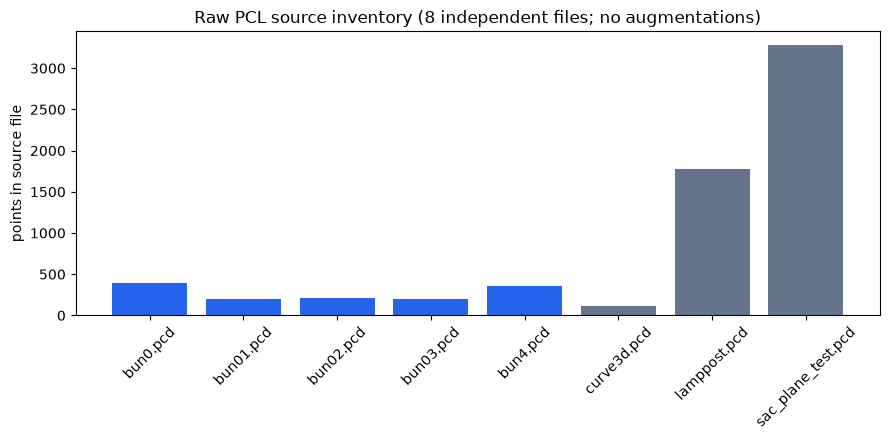

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
names = [row['source_id'] for row in records]
counts = [row['points'].shape[0] for row in records]
colors = ['#2563eb' if row['class'] == 'bunny' else '#64748b' for row in records]
ax.bar(names, counts, color=colors)
ax.set_title('Raw PCL source inventory (8 independent files; no augmentations)')
ax.set_ylabel('points in source file')
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
(ROOT / 'docs' / 'plots').mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / 'docs' / 'plots' / 'raw_inventory.png', dpi=160)
plt.show()

source: bun0.pcd
observed derived view: (256, 3) | synthetic completion: (512, 3)


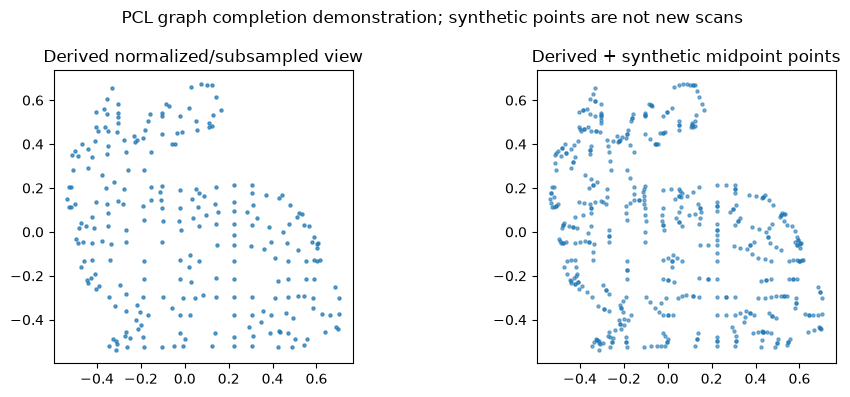

In [4]:
def normalize(points):
    centered = points - points.mean(axis=0, keepdims=True)
    scale = np.linalg.norm(centered, axis=1).max()
    return centered / max(scale, 1e-8)

def sample_fixed(points, n=256, seed=7):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(points), size=n, replace=len(points) < n)
    return points[indices]

def graph_complete(points, k=8):
    try:
        from scipy.spatial import cKDTree
    except ImportError:
        raise RuntimeError('scipy is required for graph completion')
    distances, neighbours = cKDTree(points).query(points, k=min(k + 1, len(points)))
    neighbours = np.atleast_2d(neighbours)
    source = points
    midpoints = (source + source[neighbours[:, 1]]) / 2.0
    return np.concatenate([source, midpoints], axis=0)

raw = normalize(records[0]['points'])
observed = sample_fixed(raw, n=min(256, len(raw)))
completed = graph_complete(observed, k=6)
print('source:', records[0]['source_id'])
print('observed derived view:', observed.shape, '| synthetic completion:', completed.shape)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(observed[:, 0], observed[:, 1], s=5, alpha=.7)
axes[0].set_title('Derived normalized/subsampled view')
axes[1].scatter(completed[:, 0], completed[:, 1], s=5, alpha=.55)
axes[1].set_title('Derived + synthetic midpoint points')
for axis in axes:
    axis.set_aspect('equal')
fig.suptitle('PCL graph completion demonstration; synthetic points are not new scans')
fig.tight_layout()
fig.savefig(ROOT / 'docs' / 'plots' / 'completion_before_after.png', dpi=160)
plt.show()

In [5]:
class_counts = {}
for row in records:
    class_counts[row['class']] = class_counts.get(row['class'], 0) + 1
print('source counts by manual filename label:', class_counts)
source_aware_evaluation_supported = all(count >= 2 for count in class_counts.values())
assert len({row['source_id'] for row in records}) == len(records)
if not source_aware_evaluation_supported:
    print('CLASSIFICATION METRICS DISABLED: at least one manual class has fewer than two independent source files.')
    print('This prevents a misleading augmented-copy train/validation claim.')
else:
    raise RuntimeError('Update this notebook with a source-aware split before reporting classification.')

source counts by manual filename label: {'bunny': 5, 'curve': 1, 'lamppost': 1, 'plane': 1}
CLASSIFICATION METRICS DISABLED: at least one manual class has fewer than two independent source files.
This prevents a misleading augmented-copy train/validation claim.


In [6]:
try:
    import torch
    from torch import nn

    def knn_indices(points, k):
        from scipy.spatial import cKDTree
        return cKDTree(points).query(points, k=k + 1)[1][:, 1:]

    class EdgeAttentionBlock(nn.Module):
        def __init__(self, channels):
            super().__init__()
            self.query = nn.Linear(channels, channels, bias=False)
            self.key = nn.Linear(channels, channels, bias=False)
            self.value = nn.Linear(channels, channels, bias=False)
            self.out = nn.Linear(channels, channels)

        def forward(self, x, neighbours):
            batch, points, channels = x.shape
            gather = neighbours[None, :, :, None].expand(batch, -1, -1, channels)
            keys = torch.gather(x[:, :, None, :].expand(-1, -1, neighbours.shape[1], -1), 1, gather)
            values = torch.gather(x[:, :, None, :].expand(-1, -1, neighbours.shape[1], -1), 1, gather)
            scores = (self.query(x)[:, :, None, :] * self.key(keys)).sum(-1) / channels**0.5
            weights = scores.softmax(-1)
            return x + self.out((weights[..., None] * self.value(values)).sum(2)), weights

    class PCRGNNEncoder(nn.Module):
        def __init__(self, channels=32):
            super().__init__()
            self.input = nn.Linear(3, channels)
            self.local = EdgeAttentionBlock(channels)
            self.context = EdgeAttentionBlock(channels)

        def forward(self, points, local_idx, context_idx):
            x = self.input(points)
            x, local_attention = self.local(x, local_idx)
            x, context_attention = self.context(x, context_idx)
            return x.mean(1), local_attention, context_attention

    demo = sample_fixed(normalize(records[0]['points']), n=64)
    local_idx = torch.tensor(knn_indices(demo, 6), dtype=torch.long)
    context_idx = torch.tensor(knn_indices(demo, 12), dtype=torch.long)
    embedding, local_attention, context_attention = PCRGNNEncoder()(torch.tensor(demo[None], dtype=torch.float32), local_idx, context_idx)
    print('attention encoder output:', tuple(embedding.shape), 'local weights:', tuple(local_attention.shape), 'context weights:', tuple(context_attention.shape))
except ImportError as exc:
    print('PyTorch/scipy encoder skipped:', exc)

attention encoder output: (1, 32) local weights: (1, 64, 6) context weights: (1, 64, 12)


## Learned occlusion completion → graph features

This is the end-to-end PC-RGNN-style path: a simulated one-sided occlusion produces a partial input, a learned decoder predicts missing points, and graph-attention features are built from the observed-plus-predicted cloud. The PCL files do not contain complete occlusion ground truth, so this self-supervised experiment uses a held-in-source reconstruction target and is not a generalization benchmark.

completion step 1/40 Chamfer loss=0.58989


completion step 40/40 Chamfer loss=0.20582
learned completion output: (8, 64, 3) | graph feature output: (8, 64) | final training Chamfer: 0.20372


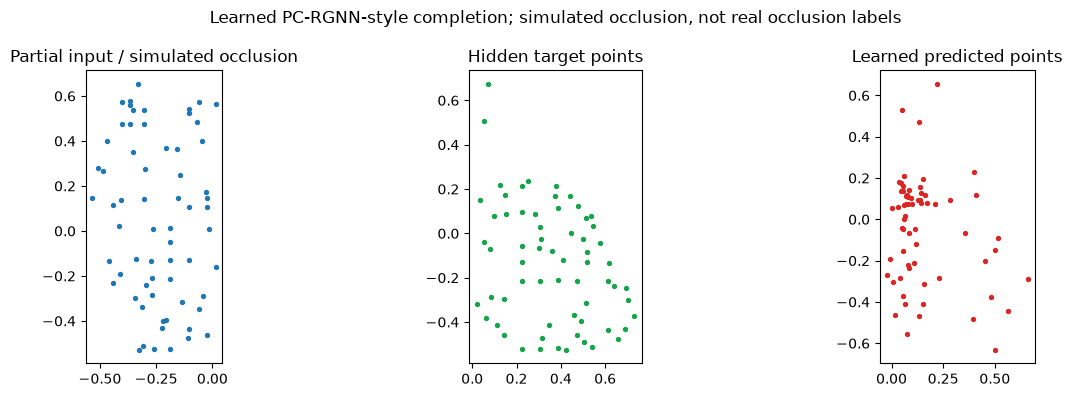

In [7]:
if 'torch' in globals():
    class BatchedEdgeAttentionBlock(nn.Module):
        def __init__(self, channels):
            super().__init__()
            self.query = nn.Linear(channels, channels, bias=False)
            self.key = nn.Linear(channels, channels, bias=False)
            self.value = nn.Linear(channels, channels, bias=False)
            self.out = nn.Linear(channels, channels)

        def forward(self, x, neighbours):
            batch, points, channels = x.shape
            if neighbours.ndim == 2:
                neighbours = neighbours[None].expand(batch, -1, -1)
            gather = neighbours[..., None].expand(-1, -1, -1, channels)
            expanded = x[:, :, None, :].expand(-1, -1, neighbours.shape[-1], -1)
            keys = torch.gather(expanded, 1, gather)
            values = keys
            scores = (self.query(x)[:, :, None, :] * self.key(keys)).sum(-1) / channels**0.5
            weights = scores.softmax(-1)
            return x + self.out((weights[..., None] * self.value(values)).sum(2))

    class LearnedPCRGNN(nn.Module):
        def __init__(self, observed_points=64, missing_points=64, channels=32):
            super().__init__()
            self.missing_points = missing_points
            self.input = nn.Linear(3, channels)
            self.local = BatchedEdgeAttentionBlock(channels)
            self.context = BatchedEdgeAttentionBlock(channels)
            self.completion_head = nn.Sequential(nn.Linear(channels, 64), nn.ReLU(), nn.Linear(64, missing_points * 3))
            self.completed_point_encoder = nn.Sequential(nn.Linear(3, channels), nn.ReLU(), nn.Linear(channels, channels))
            self.feature_head = nn.Sequential(nn.Linear(channels * 2, 64), nn.ReLU(), nn.Linear(64, 64))

        def forward(self, observed, local_idx, context_idx):
            encoded = self.input(observed)
            encoded = self.local(encoded, local_idx)
            encoded = self.context(encoded, context_idx)
            global_feature = encoded.mean(1)
            predicted_missing = self.completion_head(global_feature).view(-1, self.missing_points, 3)
            completed = torch.cat([observed, predicted_missing], dim=1)
            completed_feature = self.completed_point_encoder(completed).mean(1)
            feature = self.feature_head(torch.cat([global_feature, completed_feature], dim=1))
            return predicted_missing, feature

    def chamfer_distance(predicted, target):
        distances = torch.cdist(predicted, target)
        return distances.min(-1).values.mean() + distances.min(-2).values.mean()

    def simulated_occlusion(points, total_points=128, observed_points=64, seed=0):
        target = sample_fixed(normalize(points), n=total_points, seed=seed)
        rng = np.random.default_rng(seed)
        visibility_score = target[:, 0] + rng.normal(0, 0.01, total_points)
        order = np.argsort(visibility_score)
        return target[order[:observed_points]], target[order[observed_points:]]

    observed_batch, missing_batch = zip(*(simulated_occlusion(row['points'], seed=i) for i, row in enumerate(records)))
    observed_batch = np.stack(observed_batch).astype(np.float32)
    missing_batch = np.stack(missing_batch).astype(np.float32)
    local_batch = np.stack([knn_indices(points, 6) for points in observed_batch])
    context_batch = np.stack([knn_indices(points, 12) for points in observed_batch])
    observed_tensor = torch.tensor(observed_batch)
    missing_tensor = torch.tensor(missing_batch)
    local_tensor = torch.tensor(local_batch, dtype=torch.long)
    context_tensor = torch.tensor(context_batch, dtype=torch.long)
    learned_model = LearnedPCRGNN()
    optimizer = torch.optim.Adam(learned_model.parameters(), lr=2e-3)
    learned_model.train()
    for step in range(40):
        optimizer.zero_grad()
        predicted_missing, learned_features = learned_model(observed_tensor, local_tensor, context_tensor)
        loss = chamfer_distance(predicted_missing, missing_tensor)
        loss.backward()
        optimizer.step()
        if step in (0, 39):
            print(f'completion step {step + 1}/40 Chamfer loss={loss.item():.5f}')
    learned_model.eval()
    with torch.no_grad():
        predicted_missing, learned_features = learned_model(observed_tensor, local_tensor, context_tensor)
    final_loss = float(chamfer_distance(predicted_missing, missing_tensor).item())
    assert np.isfinite(final_loss) and learned_features.shape == (len(records), 64)
    print('learned completion output:', tuple(predicted_missing.shape), '| graph feature output:', tuple(learned_features.shape), '| final training Chamfer:', round(final_loss, 5))
    example = 0
    predicted_example = predicted_missing[example].detach().numpy()
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].scatter(observed_batch[example, :, 0], observed_batch[example, :, 1], s=8)
    axes[0].set_title('Partial input / simulated occlusion')
    axes[1].scatter(missing_batch[example, :, 0], missing_batch[example, :, 1], s=8, color='#16a34a')
    axes[1].set_title('Hidden target points')
    axes[2].scatter(predicted_example[:, 0], predicted_example[:, 1], s=8, color='#dc2626')
    axes[2].set_title('Learned predicted points')
    for axis in axes:
        axis.set_aspect('equal')
    fig.suptitle('Learned PC-RGNN-style completion; simulated occlusion, not real occlusion labels')
    fig.tight_layout()
    fig.savefig(ROOT / 'docs' / 'plots' / 'learned_completion.png', dpi=160)
    plt.show()
else:
    print('Learned completion skipped: install PyTorch to train the end-to-end completion and feature path.')

The learned decoder now predicts missing points before feature construction. Its PCL supervision is self-supervised from synthetic masks of the same raw source clouds; it is a functional architecture demonstration, not evidence of performance on real occlusions. A valid real-occlusion benchmark requires a dataset with complete/partial correspondence or official completion annotations.

## Conclusion

The PCL files pass the pinned integrity checks and the graph/attention forward pass is executable when the optional ML dependencies are installed. The completion points are synthetic and the manual labels are not official annotations. Because the source-aware class-balanced holdout is not supported by this corpus, the old augmented validation accuracy is intentionally not reproduced or presented as evidence of generalization.